# Prévision de la consommation électrique des appareils d'une maison basse consommation

Projet ST7 « Smart Cities » (CentraleSupélec × RTE).

**Objectif :** prédire, toutes les 10 minutes, la consommation électrique des appareils d'une maison, puis en tirer des recommandations pour décaler les usages hors des heures de pointe.

**Démarche :**
1. Reconstituer une série temporelle propre (les fichiers fournis sont mélangés dans le temps)
2. Explorer les profils de consommation
3. Construire des références simples (moyenne, profil horaire, persistance)
4. Comparer un modèle tabulaire (Extra Trees) et un modèle profond pour séries temporelles, **TSMixer**
5. Comparer trois normalisations pour TSMixer : min-max, z-score et **RevIN**
6. Formuler des recommandations à partir des résultats

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # masque les messages techniques de TensorFlow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import keras 
from keras import layers, ops

SEED = 0
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
plt.rcParams['figure.figsize'] = (12, 4) 

## 1. Les données

Les données proviennent de l'étude de Candanedo et al. (2017) : une maison passive en Belgique, instrumentée pendant 4,5 mois. On dispose de la température et de l'humidité de 9 pièces, de la météo d'une station voisine, de la consommation de l'éclairage, et de la cible `appliances`, la consommation des appareils **transformée par un logarithme** (log des Wh sur 10 minutes).

Les fichiers `train.csv` et `test.csv` sont un découpage aléatoire du jeu complet : `test.csv` n'a pas de cible, et **les lignes de `train.csv` ne sont pas dans l'ordre chronologique**. Pour faire de la prévision de série temporelle, il faut donc d'abord reconstituer la série.

In [2]:
train = pd.read_csv('data/train.csv', parse_dates=['date'])
test = pd.read_csv('data/test.csv', parse_dates=['date'])

print("Premières dates de train.csv :", train['date'].head(3).dt.strftime('%d/%m %H:%M').tolist())

# Réunion des deux fichiers et tri chronologique
df = pd.concat([train, test]).sort_values('date').reset_index(drop=True)
pas = df['date'].diff().dropna().value_counts()
print(f"{len(df)} mesures du {df['date'].min():%d/%m/%Y} au {df['date'].max():%d/%m/%Y}")
print("Écart entre deux mesures :", pas.to_dict())
print(f"Cible connue sur {df['appliances'].notna().mean():.0%} des pas de temps")

Premières dates de train.csv : ['26/01 12:30', '27/05 17:20', '03/02 13:00']
19735 mesures du 11/01/2016 au 27/05/2016
Écart entre deux mesures : {Timedelta('0 days 00:10:00'): 19734}
Cible connue sur 80% des pas de temps


Une fois triés, les deux fichiers forment une série **complète et régulière** au pas de 10 minutes. Les variables explicatives sont connues partout ; la cible est connue sur 80 % des pas de temps (les lignes de `train.csv`).

On écarte `rv1` et `rv2`, deux variables aléatoires ajoutées volontairement par les auteurs de l'étude pour tester leurs méthodes de sélection de variables.

In [3]:
SENSORS = (['lights']
           + [c for i in range(1, 10) for c in (f't{i}', f'rh_{i}')]
           + ['t_out', 'press_mm_hg', 'rh_out', 'windspeed', 'visibility', 'tdewpoint'])

# Variables calendaires, encodées de façon cyclique pour l'heure
heure = df['date'].dt.hour + df['date'].dt.minute / 60
df['hour_sin'] = np.sin(2 * np.pi * heure / 24)
df['hour_cos'] = np.cos(2 * np.pi * heure / 24)
df['weekend'] = (df['date'].dt.dayofweek >= 5).astype(float)
CALENDAR = ['hour_sin', 'hour_cos', 'weekend']

y = df['appliances'].values               # cible (NaN là où elle est inconnue)
wh = np.exp(df['appliances'])             # cible en Wh, pour l'exploration

## 2. Exploration

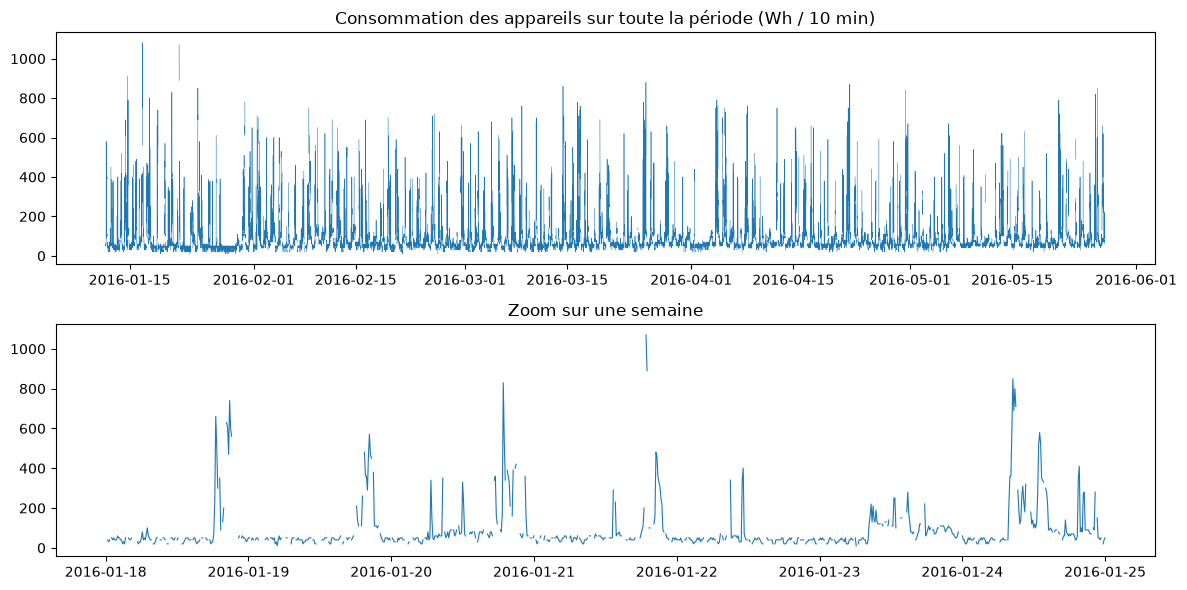

count    15788.0
mean        98.0
std        103.0
min         10.0
25%         50.0
50%         60.0
75%        100.0
max       1080.0
Name: appliances, dtype: float64


In [4]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6))
ax[0].plot(df['date'], wh, lw=0.4)
ax[0].set_title('Consommation des appareils sur toute la période (Wh / 10 min)')
semaine = df['date'].between('2016-01-18', '2016-01-25')
ax[1].plot(df.loc[semaine, 'date'], wh[semaine], lw=0.8)
ax[1].set_title('Zoom sur une semaine')
plt.tight_layout(); plt.show()

print(wh.describe().round(0))

La consommation alterne entre un **niveau de base** autour de 50 Wh (réfrigérateurs, box, veilles) et des **pics brefs et violents** qui peuvent dépasser 800 Wh. La distribution est très asymétrique, ce qui justifie la transformation logarithmique de la cible.

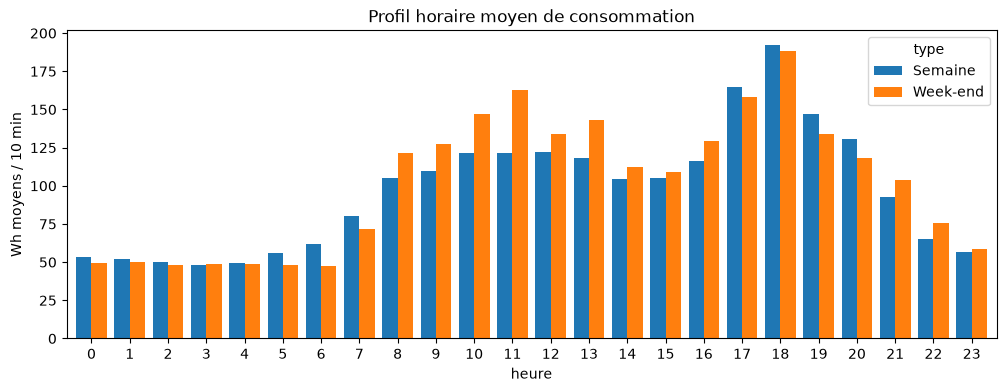

In [5]:
profil = (pd.DataFrame({'heure': df['date'].dt.hour,
                        'type': np.where(df['weekend'] == 1, 'Week-end', 'Semaine'),
                        'wh': wh})
          .dropna()
          .groupby(['heure', 'type'])['wh'].mean()
          .unstack())

profil.plot(kind='bar', width=0.8)
plt.ylabel('Wh moyens / 10 min')
plt.title('Profil horaire moyen de consommation')
plt.xticks(rotation=0); plt.show()

Le profil journalier est très marqué : consommation minimale la nuit, montée à partir de 6-7 h, puis un **pic en fin de journée (17 h - 20 h)**. Ce pic du soir coïncide avec la pointe de consommation nationale, ce qui en fait la cible naturelle des recommandations (partie 6).

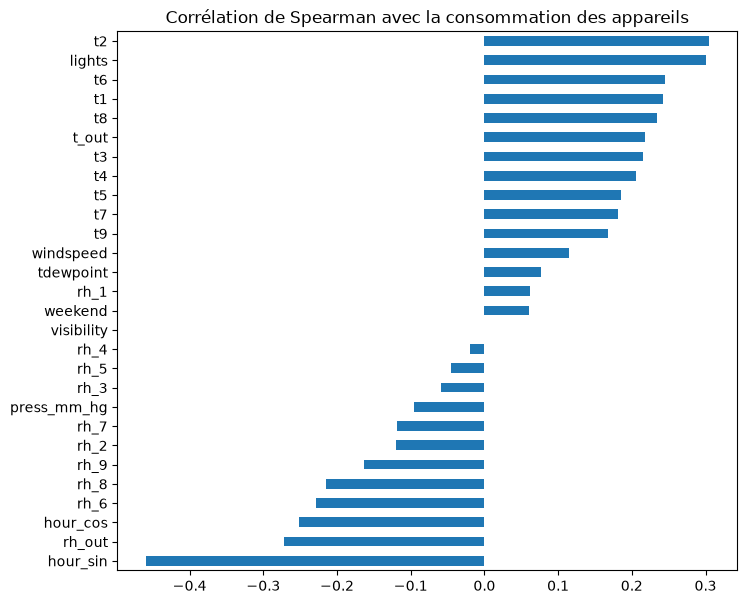

In [6]:
corr = (df[SENSORS + CALENDAR + ['appliances']].dropna()
        .corr(method='spearman')['appliances']
        .drop('appliances').sort_values())
corr.plot(kind='barh', figsize=(8, 7))
plt.title('Corrélation de Spearman avec la consommation des appareils')
plt.show()

Aucune variable n'est fortement corrélée à la cible. Les plus liées sont l'heure de la journée, l'éclairage (indicateur de présence) et l'humidité de certaines pièces (cuisine, buanderie), cohérent avec l'étude originale. La consommation dépend surtout du **comportement des occupants**, difficile à observer directement : il faut s'attendre à une prévision limitée.

## 3. Protocole d'évaluation

Pour une série temporelle, le découpage doit être **chronologique** : on entraîne sur le passé et on évalue sur le futur. Un découpage aléatoire laisserait le modèle « voir » des instants voisins de ceux qu'il doit prédire, et surestimerait ses performances.

- **Entraînement :** les 70 premiers % de la période
- **Validation :** les 10 % suivants (arrêt anticipé des réseaux)
- **Test :** les 20 derniers % (du 30 avril au 27 mai)

**Tâche :** prédire la consommation à l'instant *t* à partir des 24 heures précédentes (144 pas de 10 minutes) : capteurs, météo, calendrier, et consommation passée. Pour la consommation passée, les 20 % de pas où elle est inconnue sont complétés par la dernière valeur connue, et une variable `observed` indique si la valeur est réelle.

Les métriques sont calculées sur l'échelle logarithmique (MAE, RMSE, R²), ainsi qu'en Wh (MAE_Wh) pour une lecture concrète.

In [7]:
df['observed'] = df['appliances'].notna().astype(float)
df['app_past'] = df['appliances'].ffill().bfill()
FEATURES = SENSORS + CALENDAR + ['observed', 'app_past']
TARGET_IDX = FEATURES.index('app_past')

L = 144  # fenêtre d'entrée : 24 h

labeled = np.where(df['appliances'].notna())[0]
labeled = labeled[labeled >= L]
t_val, t_test = df['date'].quantile(0.7), df['date'].quantile(0.8)
d = df['date'].values[labeled]
idx_train = labeled[d < t_val]
idx_val = labeled[(d >= t_val) & (d < t_test)]
idx_test = labeled[d >= t_test]
print(f"Train : {len(idx_train)}  |  Validation : {len(idx_val)}  |  Test : {len(idx_test)}")
print(f"Test à partir du {t_test:%d/%m/%Y %H:%M}")

def evaluate(y_true, y_pred):
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'R2': r2_score(y_true, y_pred),
            'MAE_Wh': mean_absolute_error(np.exp(y_true), np.exp(y_pred))}

results = {}
y_test = y[idx_test]

Train : 10921  |  Validation : 1580  |  Test : 3175
Test à partir du 30/04/2016 08:12


## 4. Références simples

Un modèle n'a d'intérêt que s'il fait mieux que des règles triviales :
- **Moyenne** : on prédit toujours la consommation moyenne d'entraînement
- **Profil horaire** : on prédit la moyenne observée à la même heure
- **Persistance** : on prédit la dernière valeur connue

In [8]:
y_prev = df['app_past'].shift(1).values   # dernière consommation connue avant t
heures = df['date'].dt.hour.values
profil_train = pd.Series(y[idx_train]).groupby(heures[idx_train]).mean()

results['Moyenne'] = evaluate(y_test, np.full(len(y_test), y[idx_train].mean()))
results['Profil horaire'] = evaluate(y_test, profil_train.reindex(heures[idx_test]).values)
results['Persistance'] = evaluate(y_test, y_prev[idx_test])
pd.DataFrame(results).T.round(3)

,MAE,RMSE,R2,MAE_Wh
Moyenne,0.407,0.570,-0.013,44.426
Profil horaire,0.343,0.503,0.212,39.894
Persistance,0.224,0.374,0.566,29.647


La persistance est une référence exigeante : la consommation reste souvent stable d'un pas de 10 minutes au suivant. Tout modèle devra la battre pour être utile.

## 5. Modèles

### 5.1 Extra Trees

Un modèle tabulaire classique, qui a obtenu de bons résultats sur ce jeu de données. Il reçoit les variables à l'instant *t*, le calendrier, la dernière consommation connue et sa moyenne sur l'heure écoulée.

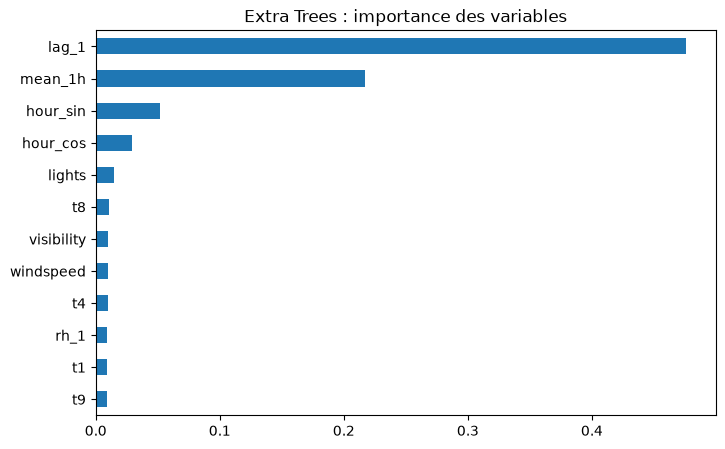

In [9]:
tab = df[SENSORS + CALENDAR].copy()
tab['lag_1'] = y_prev
tab['mean_1h'] = pd.Series(y_prev).rolling(6, min_periods=1).mean().values

idx_fit = np.r_[idx_train, idx_val]
et = ExtraTreesRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED)
et.fit(tab.values[idx_fit], y[idx_fit])
pred_et = et.predict(tab.values[idx_test])
results['Extra Trees'] = evaluate(y_test, pred_et)

importance = pd.Series(et.feature_importances_, index=tab.columns).sort_values()
importance.tail(12).plot(kind='barh', figsize=(8, 5))
plt.title('Extra Trees : importance des variables'); plt.show()

### 5.2 TSMixer

TSMixer (Chen et al., 2023) est une architecture entièrement construite avec des perceptrons multicouches. Chaque bloc alterne deux opérations, chacune avec une connexion résiduelle :
- un **mélange temporel** : une couche dense appliquée le long de l'axe du temps, partagée entre toutes les variables
- un **mélange des variables** : un MLP à deux couches appliqué à chaque pas de temps, partagé dans le temps

Une **projection temporelle** finale transforme la fenêtre de 144 pas en prédiction du pas suivant.

### 5.3 Normalisation RevIN

Les séries temporelles changent de niveau au cours du temps (ici : chauffage en hiver, pas au printemps), si bien que la période de test ne ressemble pas exactement à la période d'entraînement. **RevIN** (Kim et al., 2022) traite ce problème en deux temps :
1. chaque fenêtre d'entrée est normalisée avec **sa propre** moyenne et son propre écart-type, variable par variable, puis transformée par des paramètres appris γ et β
2. la sortie du modèle est **dé-normalisée** avec les mêmes statistiques, pour revenir à l'échelle de la fenêtre

Le modèle n'a ainsi à apprendre que l'écart par rapport au niveau récent. On le compare à deux normalisations globales classiques, calculées **sur la période d'entraînement uniquement** : min-max et z-score.

In [10]:
class RevIN(layers.Layer):
    '''Normalisation d'instance réversible (Kim et al., ICLR 2022).'''
    def __init__(self, eps=1e-5, **kwargs):
        super().__init__(**kwargs)
        self.eps = eps

    def build(self, input_shape):
        n = input_shape[-1]
        self.gamma = self.add_weight(shape=(n,), initializer='ones', name='gamma')
        self.beta = self.add_weight(shape=(n,), initializer='zeros', name='beta')

    def call(self, x):
        mean = ops.mean(x, axis=1, keepdims=True)
        std = ops.sqrt(ops.var(x, axis=1, keepdims=True) + self.eps)
        return (x - mean) / std * self.gamma + self.beta, mean, std


class RevINDenorm(layers.Layer):
    '''Étape inverse de RevIN, avec les statistiques de la fenêtre d'entrée.'''
    def __init__(self, revin, **kwargs):
        super().__init__(**kwargs)
        self.revin = revin

    def call(self, y, mean, std):
        r = self.revin
        return (y - r.beta) / (r.gamma + r.eps) * std + mean


def mixer_block(x, dropout, ff_dim):
    n_steps, n_features = x.shape[1], x.shape[2]
    # Mélange temporel : dense le long de l'axe du temps
    z = layers.LayerNormalization(axis=[-2, -1])(x)
    z = layers.Permute((2, 1))(z)
    z = layers.Dense(n_steps, activation='relu')(z)
    z = layers.Permute((2, 1))(z)
    x = layers.Add()([x, layers.Dropout(dropout)(z)])
    # Mélange des variables : MLP à chaque pas de temps
    z = layers.LayerNormalization(axis=[-2, -1])(x)
    z = layers.Dense(ff_dim, activation='relu')(z)
    z = layers.Dropout(dropout)(z)
    z = layers.Dense(n_features)(z)
    z = layers.Dropout(dropout)(z)
    return layers.Add()([x, z])


def build_tsmixer(n_features, use_revin, n_blocks=2, dropout=0.1, ff_dim=64):
    inputs = keras.Input((L, n_features))
    x = inputs
    if use_revin:
        revin = RevIN()
        x, mean, std = revin(x)
    for _ in range(n_blocks):
        x = mixer_block(x, dropout, ff_dim)
    # Projection temporelle : 144 pas -> 1 pas
    x = layers.Permute((2, 1))(x)
    x = layers.Dense(1)(x)
    x = layers.Permute((2, 1))(x)
    if use_revin:
        x = RevINDenorm(revin)(x, mean, std)
    outputs = layers.Lambda(lambda t: t[:, 0, TARGET_IDX])(x)
    return keras.Model(inputs, outputs)

In [11]:
X_raw = df[FEATURES].values.astype('float32')
train_rows = np.arange(idx_train.max())   # statistiques calculées sur la période d'entraînement

def make_windows(idx, A):
    return np.stack([A[i - L:i] for i in idx])

def train_tsmixer(normalisation):
    A = X_raw.copy()
    if normalisation == 'z-score':
        center, scale = A[train_rows].mean(0), A[train_rows].std(0) + 1e-8
    elif normalisation == 'min-max':
        center = A[train_rows].min(0)
        scale = A[train_rows].max(0) - center + 1e-8
    else:  # RevIN : pas de normalisation globale, tout se fait dans le réseau
        center, scale = np.zeros(A.shape[1]), np.ones(A.shape[1])
    A = (A - center) / scale
    c, s = center[TARGET_IDX], scale[TARGET_IDX]
    y_norm = (y - c) / s

    keras.utils.set_random_seed(SEED)
    model = build_tsmixer(A.shape[1], use_revin=(normalisation == 'RevIN'))
    model.compile(optimizer='adam', loss='mse')
    history = model.fit(
        make_windows(idx_train, A), y_norm[idx_train],
        validation_data=(make_windows(idx_val, A), y_norm[idx_val]),
        epochs=30, batch_size=64, verbose=0,
        callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
    pred = model.predict(make_windows(idx_test, A), verbose=0) * s + c
    print(f"{normalisation:8s} : {len(history.history['loss'])} époques")
    return pred, history

predictions, histories = {}, {}
for norm in ['min-max', 'z-score', 'RevIN']:
    predictions[norm], histories[norm] = train_tsmixer(norm)
    results[f'TSMixer + {norm}'] = evaluate(y_test, predictions[norm])

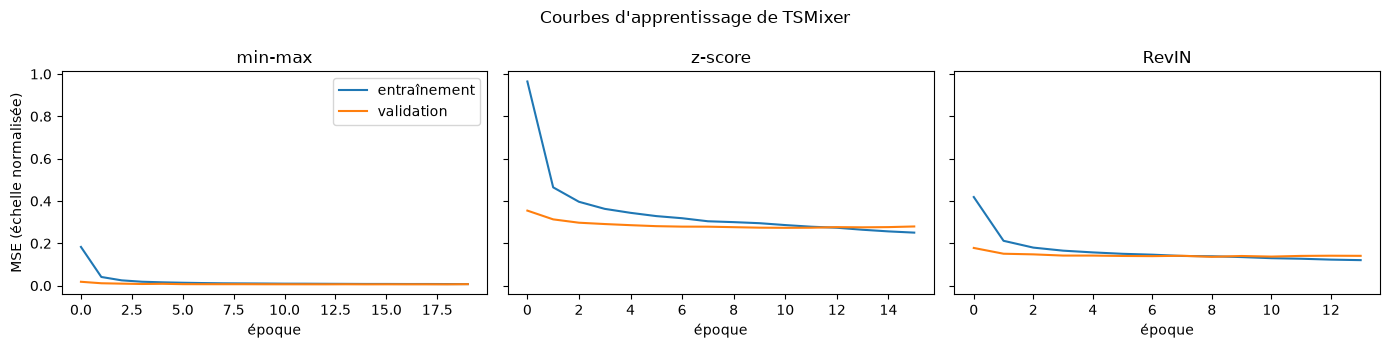

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for a, (norm, h) in zip(ax, histories.items()):
    a.plot(h.history['loss'], label='entraînement')
    a.plot(h.history['val_loss'], label='validation')
    a.set_title(norm); a.set_xlabel('époque')
ax[0].set_ylabel('MSE (échelle normalisée)'); ax[0].legend()
plt.suptitle("Courbes d'apprentissage de TSMixer"); plt.tight_layout(); plt.show()

## 6. Résultats

In [13]:
table = pd.DataFrame(results).T
table.round(3)

,MAE,RMSE,R2,MAE_Wh
Moyenne,0.407,0.570,-0.013,44.426
Profil horaire,0.343,0.503,0.212,39.894
Persistance,0.224,0.374,0.566,29.647
Extra Trees,0.246,0.357,0.603,30.689
TSMixer + min-max,0.255,0.371,0.572,30.214
TSMixer + z-score,0.256,0.369,0.575,30.406
TSMixer + RevIN,0.246,0.361,0.595,29.760


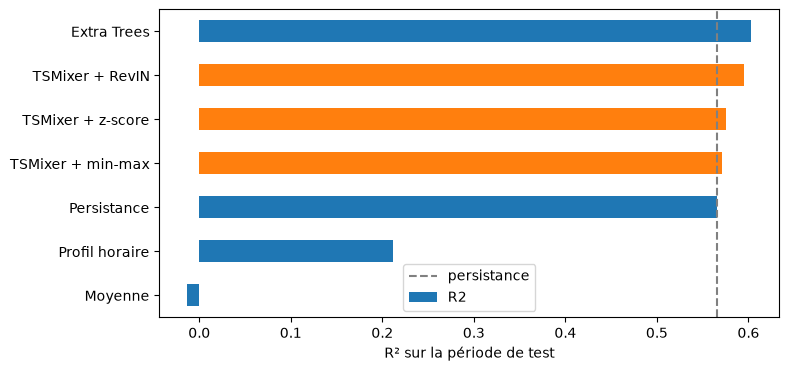

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
table['R2'].sort_values().plot(kind='barh', ax=ax,
    color=['tab:orange' if 'TSMixer' in n else 'tab:blue' for n in table['R2'].sort_values().index])
ax.axvline(results['Persistance']['R2'], ls='--', c='grey', label='persistance')
ax.set_xlabel('R² sur la période de test'); ax.legend(); plt.show()

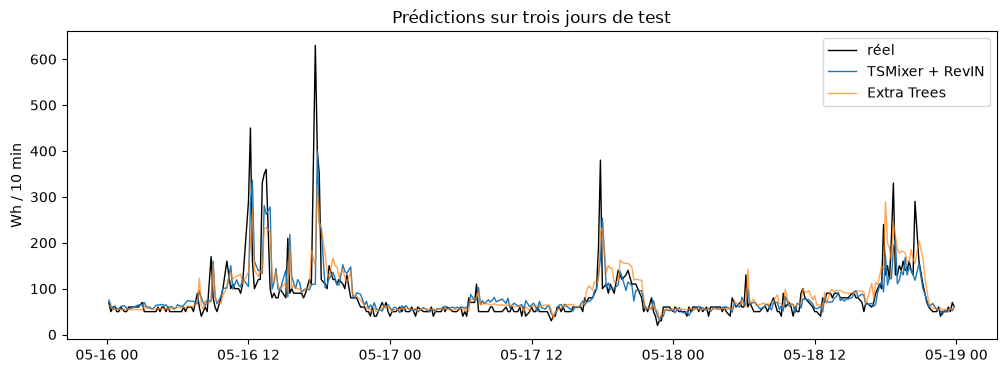

In [15]:
jours = (df['date'].values[idx_test] >= np.datetime64('2016-05-16')) & \
        (df['date'].values[idx_test] < np.datetime64('2016-05-19'))
plt.figure(figsize=(12, 4))
plt.plot(df['date'].values[idx_test][jours], np.exp(y_test[jours]), 'k', lw=1, label='réel')
plt.plot(df['date'].values[idx_test][jours], np.exp(predictions['RevIN'][jours]), lw=1, label='TSMixer + RevIN')
plt.plot(df['date'].values[idx_test][jours], np.exp(pred_et[jours]), lw=1, alpha=0.7, label='Extra Trees')
plt.ylabel('Wh / 10 min'); plt.title('Prédictions sur trois jours de test'); plt.legend(); plt.show()

**Lecture des résultats**

- Les références triviales encadrent le problème : prédire la moyenne ne sert à rien (R² ≈ 0), et la simple persistance explique déjà plus de la moitié de la variance.
- **La normalisation compte pour TSMixer** : RevIN donne le meilleur TSMixer, devant le min-max et le z-score. C'est cohérent avec l'article : la dé-normalisation permet au modèle de suivre les changements de niveau entre l'hiver (entraînement) et la fin du printemps (test).
- **Les modèles appris ne battent la persistance que de peu.** Ils suivent bien le niveau de base et les tendances, mais aucun ne sait anticiper les pics : un pic correspond à la mise en route d'un appareil (four, lave-linge), une décision humaine que les capteurs de température et d'humidité ne permettent pas de prévoir.
- Ces résultats reposent sur une seule exécution et une seule période de test. Les écarts de quelques centièmes de R² entre les meilleurs modèles ne sont pas significatifs.

## 7. Recommandations

La prévision fine des pics étant hors de portée, les recommandations s'appuient plutôt sur les **régularités** mises en évidence : le profil horaire et le poids de la pointe du soir.

In [16]:
conso = pd.DataFrame({'heure': df['date'].dt.hour, 'wh': wh}).dropna()
pointe = conso['heure'].between(17, 20)
part_pointe = conso.loc[pointe, 'wh'].sum() / conso['wh'].sum()
print(f"La tranche 17 h - 21 h représente {pointe.mean():.0%} du temps "
      f"mais {part_pointe:.0%} de la consommation des appareils.")

# Part des pics (au-dessus du 90e centile) survenant en soirée
seuil = conso['wh'].quantile(0.9)
pics = conso[conso['wh'] > seuil]
print(f"{pics['heure'].between(17, 20).mean():.0%} des pics de consommation (> {seuil:.0f} Wh / 10 min) "
      "ont lieu entre 17 h et 21 h.")

La tranche 17 h - 21 h représente 17% du temps mais 27% de la consommation des appareils.
33% des pics de consommation (> 200 Wh / 10 min) ont lieu entre 17 h et 21 h.


À partir de ces constats :

1. **Décaler les appareils programmables hors de 17 h - 21 h.** Le lave-linge, le sèche-linge et le lave-vaisselle (présents dans la buanderie et la cuisine, les pièces les plus liées à la consommation) peuvent être lancés en différé la nuit ou en milieu de journée. C'est le levier le plus simple, et il soulage le réseau au moment de sa pointe.
2. **Réduire le talon de consommation.** Le niveau de base d'environ 50 Wh toutes les 10 minutes, soit environ 300 W en continu, est présent jour et nuit : veilles, box, équipements réseau. Des multiprises coupe-veille agissent sur ces 24 heures.
3. **Utiliser la prévision pour planifier, pas pour alerter.** Le modèle prévoit correctement le niveau de consommation de la journée à venir ; il peut servir à estimer à l'avance la consommation d'une journée et les créneaux les plus chargés, pas à anticiper chaque pic.

## 8. Limites et pistes d'amélioration

- **Une seule maison** et 4,5 mois de données : les conclusions ne se généralisent pas telles quelles.
- **Les pics sont imprévisibles** avec ces capteurs. Des données d'occupation (présence, CO₂, bruit) ou la consommation individuelle des appareils amélioreraient nettement la prévision.
- **Évaluation à renforcer** : plusieurs graines aléatoires et une validation glissante (*walk-forward*) sur plusieurs périodes de test.
- **Horizons plus longs** : prédire les prochaines heures plutôt que les 10 prochaines minutes, là où RevIN apporte le plus d'après la littérature.
- **Signal réseau** : croiser les recommandations avec un signal de tension du réseau ou un tarif heures pleines / heures creuses, pour passer d'un conseil générique à un plan de consommation personnalisé.

## Références

- L. M. Candanedo, V. Feldheim, D. Deramaix. *Data driven prediction models of energy use of appliances in a low-energy house.* Energy and Buildings, 2017.
- S.-A. Chen, C.-L. Li, N. Yoder, S. Ö. Arık, T. Pfister. *TSMixer: An All-MLP Architecture for Time Series Forecasting.* TMLR, 2023.
- T. Kim et al. *Reversible Instance Normalization for Accurate Time-Series Forecasting against Distribution Shift.* ICLR, 2022.